# SVMによるクラス分類
このノートブックでは、CSIデータから特徴量（「二乗平均平方根」「標準偏差」「最大値」「最小値」）を抽出し、SVMでクラス分類を行います。

In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Hiragino Sans'  # macOS標準日本語フォント
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
import importlib
import data_utils
import preprocess
import feature_extraction
importlib.reload(data_utils)
importlib.reload(preprocess)
importlib.reload(feature_extraction)
from data_utils import *
from preprocess import *
from feature_extraction import *

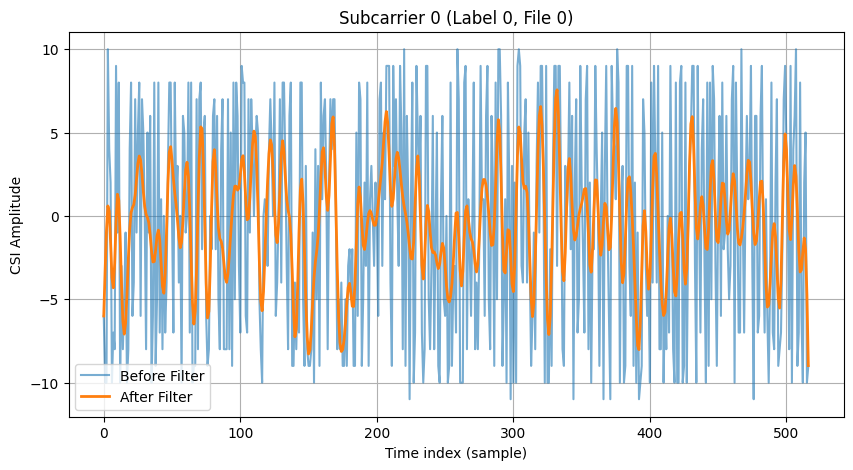

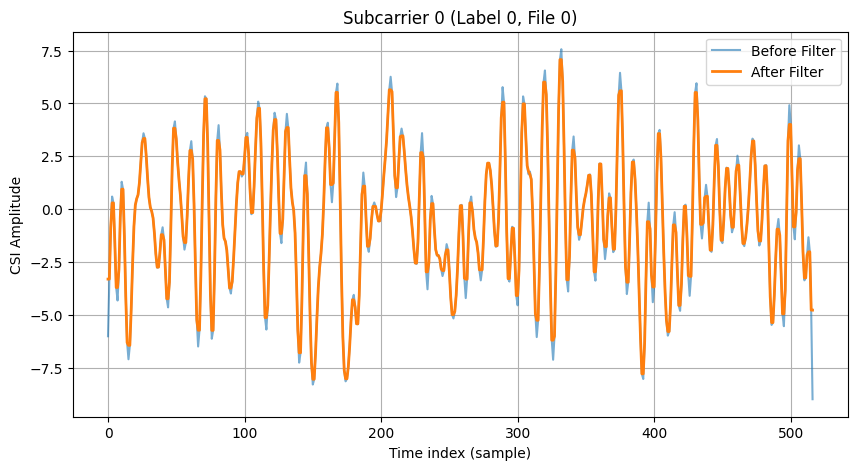

In [5]:
# 定数
LABEL_COUNT = 18  # ラベル数（必要に応じて変更）
SAMPLING_RATE = 70  # サンプリングレート
data_folder = "../data/20250809"
file_paths = [f for f in os.listdir(data_folder) if f.endswith('.txt')]

# データのロード
row_data, row_csi = load_csi_data(LABEL_COUNT, data_folder, file_paths)

# 振幅と位相の分割
row_amp, row_phase = split_amp_phase(row_csi)

# 0サブキャリア削除
row_amp, orig_subcarriers_num, new_subcarriers_num = remove_zero_subcarriers(row_amp)

# 前処理（バターワースフィルタ）
butter_filtered_csi, _ = butter_lowpass_filter_csi(row_amp, SAMPLING_RATE)

# 前処理（メディアンフィルタ）
median_filtered_csi, _ = median_filter_csi(butter_filtered_csi)

# 500msごとに分割
split_data, split_csi = split_by_interval(row_data, median_filtered_csi, interval_ms=500)

# 分割データの連結
merged_split_data, merged_split_csi = merge_split_data(split_data, split_csi)

In [6]:
# ラベルグループ化（必要に応じて変更）
target_labels = [[0,3,6], [1,4,7], [2,5,8], [9,12,15], [10,13,16], [11,14,17]]
restored_split_csi = group_labels_by_indices(merged_split_csi, target_labels)

# 特徴量抽出（指定特徴量のみ）
feature_list = ["二乗平均平方根", "標準偏差", "最大値", "最小値"]
X, y, feature_names = create_feature_matrix(restored_split_csi, SAMPLING_RATE, use_additional=False, feature_list=feature_list)
print(f"抽出された特徴量数: {len(feature_names)}")
print("特徴量名リスト例:", feature_names)

抽出された特徴量数: 664
特徴量名リスト例: ['subc0_標準偏差', 'subc0_最大値', 'subc0_最小値', 'subc0_二乗平均平方根', 'subc1_標準偏差', 'subc1_最大値', 'subc1_最小値', 'subc1_二乗平均平方根', 'subc2_標準偏差', 'subc2_最大値', 'subc2_最小値', 'subc2_二乗平均平方根', 'subc3_標準偏差', 'subc3_最大値', 'subc3_最小値', 'subc3_二乗平均平方根', 'subc4_標準偏差', 'subc4_最大値', 'subc4_最小値', 'subc4_二乗平均平方根', 'subc5_標準偏差', 'subc5_最大値', 'subc5_最小値', 'subc5_二乗平均平方根', 'subc6_標準偏差', 'subc6_最大値', 'subc6_最小値', 'subc6_二乗平均平方根', 'subc7_標準偏差', 'subc7_最大値', 'subc7_最小値', 'subc7_二乗平均平方根', 'subc8_標準偏差', 'subc8_最大値', 'subc8_最小値', 'subc8_二乗平均平方根', 'subc9_標準偏差', 'subc9_最大値', 'subc9_最小値', 'subc9_二乗平均平方根', 'subc10_標準偏差', 'subc10_最大値', 'subc10_最小値', 'subc10_二乗平均平方根', 'subc11_標準偏差', 'subc11_最大値', 'subc11_最小値', 'subc11_二乗平均平方根', 'subc12_標準偏差', 'subc12_最大値', 'subc12_最小値', 'subc12_二乗平均平方根', 'subc13_標準偏差', 'subc13_最大値', 'subc13_最小値', 'subc13_二乗平均平方根', 'subc14_標準偏差', 'subc14_最大値', 'subc14_最小値', 'subc14_二乗平均平方根', 'subc15_標準偏差', 'subc15_最大値', 'subc15_最小値', 'subc15_二乗平均平方根', 'subc16_標準偏差', 'subc16_最大値', 'subc16_最

In [7]:
# データ分割
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# SVMモデルの学習
model = SVC(kernel='rbf', C=1.0, gamma='scale')
model.fit(X_train, y_train)

# 予測と評価
y_pred = model.predict(X_test)
print('分類レポート:')
print(classification_report(y_test, y_pred))
print('混同行列:')
print(confusion_matrix(y_test, y_pred))

分類レポート:
              precision    recall  f1-score   support

           0       0.30      0.40      0.35        84
           1       0.36      0.45      0.40        78
           2       0.18      0.10      0.13        80
           3       0.30      0.49      0.38        87
           4       0.43      0.30      0.35        83
           5       0.30      0.16      0.21        86

    accuracy                           0.32       498
   macro avg       0.31      0.32      0.30       498
weighted avg       0.31      0.32      0.30       498

混同行列:
[[34 12  4 25  4  5]
 [12 35  4 10 12  5]
 [20 16  8 17  9 10]
 [21  8  7 43  4  4]
 [ 6 14 11 19 25  8]
 [19 12 10 27  4 14]]


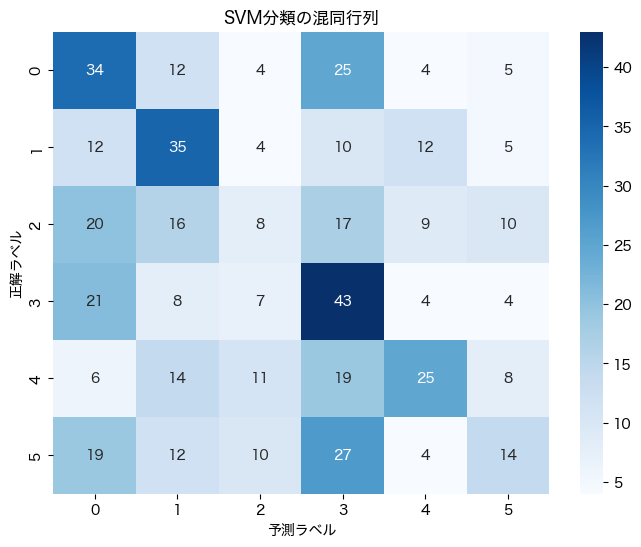

In [10]:
# 混同行列の可視化
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('予測ラベル')
plt.ylabel('正解ラベル')
plt.title('SVM分類の混同行列')
plt.show()